# Phase 5a — Tabular models (no text yet)

**Goal:** beat the best day-0 rule ("phrase, then CVSS (CNA)": 28.1% of exploited CVEs at K = 110/month, 42.7% at
K = 305 on validation) using only structured publication-day information.
**Selection metric:** recall@K per calendar month (never AUC). The test set is not touched.

In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "mpl")); os.environ.setdefault("LOKY_MAX_CPU_COUNT", "8")
warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from metrics import recall_at_k, recall_curve, random_recall_at_k, bootstrap_recall_at_k, ci_table, pr_auc, recall_at_budget
from description_leak import PHRASES, phrase_flags
from features import load_kev_raw, clean_vendor, kev_history_features
from tabular_models import build_X, make_lr, make_hgb, evaluate, grid_search, views

FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
BLUE, ORANGE, AQUA, VIOLET, INK, INK2, GRID, SURF = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "font.size": 9.5})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
def save(fig, name): fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

dev = pd.read_parquet(ROOT / "data" / "dev.parquet")
kev = load_kev_raw(sorted((ROOT / "data" / "raw").glob("kev_*.csv"))[-1])
K_MAIN, K_GEN = 110, 305                       # fixed from train in Phase 4
val_months = dev.loc[dev["split"] == "val", "published"].dt.to_period("M").nunique()
FRAC = K_MAIN / (dev["split"].eq("val").sum() / val_months)
dev["phrase_day0"] = phrase_flags(dev["description_day0"], PHRASES).any(axis=1)
print(f"dev: {len(dev):,} CVEs ({int(dev['label'].sum())} exploited); KEV snapshot rows: {len(kev):,}")

dev: 93,842 CVEs (319 exploited); KEV snapshot rows: 1,786


## 1. Features: what is known on publication day
| group | features | source |
|---|---|---|
| CVSS (CNA only, Decision 9) | score, has-score flag, base-metric letters (AV, AC, PR, UI, S, C, I, A, AT) | the CNA's own vector |
| weakness (Decision 10a) | CNA CWE, number of CNA CWEs | CNA weakness entry |
| who / what | vendor (cleaned; CNA if missing), CNA | CNA "affected" block |
| text-derived (no NLP yet) | exploitation phrase in `description_day0`, description length | Decision 10c |
| **KEV history (new)** | vendor's KEV entries all-time and last 365 days (log), days since its last KEV entry, any-KEV flag, product's KEV entries | KEV entries with dateAdded **strictly before** publication, **never the CVE's own entry** |

KEV `vendorProject` names are mapped with the same `clean_vendor` rule plus four spelling aliases
(e.g. KEV "Juniper" = CNA "Juniper Networks").

In [2]:
X = build_X(dev, kev)
vk = set(clean_vendor(dev["vendor"]).dropna())
print(f"KEV rows whose vendor matches a dev CVE vendor: {kev['vkey'].isin(vk).mean():.1%} "
      f"({kev['vkey'].isin(vk).sum():,} of {len(kev):,}); KEV vendors matched: {pd.Series(kev['vkey'].unique()).isin(vk).mean():.1%}")
neg_gap = dev[dev["days_to_kev"] < 0]
print(f"leakage guard: {len(neg_gap)} dev CVEs were in KEV before NVD published them; their own entry is excluded "
      f"(checked in features._history: dateAdded < publication AND cve_id != own)")
tr = dev["split"].eq("train")
t = pd.DataFrame({"vendor has earlier KEV entries": X.loc[tr, "vendor_kev_any"].map({1: "yes", 0: "no"}), "label": dev.loc[tr, "label"]})
g = t.groupby("vendor has earlier KEV entries")["label"].agg(CVEs="size", exploited="sum")
g["rate_%"] = (100 * g["exploited"] / g["CVEs"]).round(2); g["share_of_exploited_%"] = (100 * g["exploited"] / g["exploited"].sum()).round(1)
print("train only:"); display(g)
print(f"feature matrix: {X.shape[0]:,} rows x {X.shape[1]} columns")

KEV rows whose vendor matches a dev CVE vendor: 89.8% (1,603 of 1,786); KEV vendors matched: 61.4%
leakage guard: 52 dev CVEs were in KEV before NVD published them; their own entry is excluded (checked in features._history: dateAdded < publication AND cve_id != own)
train only:


,CVEs,exploited,rate_%,share_of_exploited_%
vendor has earlier KEV entries,,,,
no,55499,58,0.10,23.1
yes,18769,193,1.03,76.9


feature matrix: 93,842 rows x 22 columns


**Takeaway**: 22 publication-day features. KEV `vendorProject` names match a dev CVE vendor for **89.8%** of KEV rows (61% of KEV vendors; the unmatched ones are mostly vendors whose CVEs are published by MITRE with vendor 'n/a'). The new KEV-history signal is strong and day-0 safe: in train, CVEs from a vendor with **earlier** KEV entries are exploited at **1.03%** vs **0.10%** for the rest (10×), and they contain **77%** of exploited CVEs while being only 25% of CVEs. The own-entry guard matters for 52 dev CVEs that were in KEV before NVD published them.

## 2. Evaluation protocol
Validation alone has only 68 exploited CVEs (CI ≈ ±10 points), so every candidate is scored on **three views
inside dev**, each fitting on the past and scoring the future:
* **val** — fit on train (2022-01 → 2024-06), score 2024-H2 (recall@110 and @305 per month)
* **walk-forward** — fit 2022 → score 2023; fit 2022–2023 → score 2024-H1 (recall@110 per month)
* **grouped CV** inside train — 5 folds grouped by `cv_group` (vendor|month), so twin CVEs never sit on both
  sides; recall at the same share-of-month budget (3.4%) because folds mix months. Reported, not used to select.

**Selection score = mean recall@110 over the three periods (WF 2023, WF 2024-H1, val), equal weights** — the
selection rule for every Phase 5 model. The worst fold is reported too. The rules are scored on exactly the same views:

In [3]:
rule_scores = {"CVSS (CNA) ranking": dev["cvss_cna_score"].fillna(-1),
               "phrase, then CVSS (CNA)": 100 * dev["phrase_day0"] + dev["cvss_cna_score"].fillna(-1)}
rows = []
for name, s in rule_scores.items():
    r = {"method": name}
    for v, (_, ev) in views(dev).items():
        r[f"{v}@{K_MAIN}"] = recall_at_k(dev[ev], s[ev], K_MAIN)
    ev = dev["split"].eq("val").to_numpy()
    r[f"val@{K_GEN}"] = recall_at_k(dev[ev], s[ev], K_GEN)
    r["wf_mean"] = np.mean([r[f"wf_2023@{K_MAIN}"], r[f"wf_2024h1@{K_MAIN}"]]); r["wf_worst"] = min(r[f"wf_2023@{K_MAIN}"], r[f"wf_2024h1@{K_MAIN}"])
    r["selection"] = np.mean([r[f"wf_2023@{K_MAIN}"], r[f"wf_2024h1@{K_MAIN}"], r[f"val@{K_MAIN}"]])
    rows.append(r)
rules_tbl = pd.DataFrame(rows).set_index("method")
for v, (_, ev) in views(dev).items():
    print(f"{v:10s}: {ev.sum():>6,} CVEs, {int(dev.loc[ev, 'label'].sum()):>3} exploited, random recall@{K_MAIN} = {random_recall_at_k(dev[ev], K_MAIN):.1%}")
display((100 * rules_tbl).round(1))

val       : 19,574 CVEs,  68 exploited, random recall@110 = 3.5%
wf_2023   : 28,816 CVEs, 121 exploited, random recall@110 = 4.6%
wf_2024h1 : 20,379 CVEs,  45 exploited, random recall@110 = 3.3%


,val@110,wf_2023@110,wf_2024h1@110,val@305,wf_mean,wf_worst,selection
method,,,,,,,
CVSS (CNA) ranking,23.7,20.3,28.4,38.3,24.4,20.3,24.1
"phrase, then CVSS (CNA)",28.1,39.3,34.9,42.7,37.1,34.9,34.1


**Takeaway**: On the same views the best rule ('phrase, then CVSS (CNA)') scores **28.1%** on val, **39.3%** on 2023 and **34.9%** on 2024-H1 at K = 110 (selection score = three-period mean **34.1%**). A random pick gets 3–5%. Each view has only 45–121 exploited CVEs, which is why we average the three periods rather than trust any single one.

## 3. Logistic regression
One-hot encoding of vendor, CNA, CWE and CVSS letters (categories seen fewer than `min_freq` times in the
training part are grouped as "infrequent"), standardised numeric features, **class_weight = balanced** for the
1-in-300 imbalance. Grid: regularisation C × rare-category threshold.

In [4]:
LR_GRID = {"C": [0.01, 0.03, 0.1, 0.3, 1.0], "min_freq": [5, 20]}
lr_res = grid_search("lr", LR_GRID, dev, X, K_MAIN, K_GEN, FRAC, log=lambda s: None)
show = ["C", "min_freq", f"val@{K_MAIN}", f"val@{K_GEN}", f"wf_2023@{K_MAIN}", f"wf_2024h1@{K_MAIN}", "wf_worst", f"gcv@{FRAC:.1%}", "val_pr_auc", "selection"]
display(lr_res[show].round(3)); lr_res.to_csv(TAB / "05a_lr_grid.csv", index=False)
best_lr = lr_res.iloc[0][["C", "min_freq"]].to_dict(); best_lr["min_freq"] = int(best_lr["min_freq"])
print("selected LR:", best_lr)

,C,min_freq,val@110,val@305,wf_2023@110,wf_2024h1@110,wf_worst,gcv@3.4%,val_pr_auc,selection
0,0.30,5,0.309,0.588,0.537,0.289,0.289,0.462,0.071,0.378
1,0.03,20,0.397,0.706,0.488,0.244,0.244,0.455,0.086,0.376
2,0.10,20,0.382,0.676,0.479,0.267,0.267,0.454,0.083,0.376
3,0.10,5,0.353,0.632,0.521,0.244,0.244,0.463,0.100,0.373
4,0.30,20,0.397,0.618,0.471,0.244,0.244,0.451,0.065,0.371
5,0.03,5,0.338,0.676,0.521,0.222,0.222,0.468,0.088,0.360
6,1.00,20,0.353,0.574,0.455,0.267,0.267,0.451,0.051,0.358
7,0.01,5,0.338,0.618,0.504,0.222,0.222,0.466,0.087,0.355
8,0.01,20,0.353,0.676,0.471,0.222,0.222,0.460,0.086,0.349
9,1.00,5,0.279,0.529,0.463,0.267,0.267,0.457,0.052,0.336


selected LR: {'C': 0.3, 'min_freq': 5}


**Takeaway**: Under the three-period rule the selected logistic regression is C = 0.3 with rare categories < 5 grouped (selection 37.8%), essentially tied with C = 0.03 / min_freq 20 (37.6%). All ten settings fall within 33.6–37.8%, so the choice is driven by noise. The chosen setting is strong on 2023 (**53.7%**) but weak on val (**30.9%**) and 2024-H1 (**28.9%, below the best rule's 34.9%**): logistic regression is the least stable model across periods.

## 4. Gradient boosting (HistGradientBoostingClassifier, Decision 7)
Trees can combine signals ("Microsoft **and** network **and** vendor had a KEV entry last month") that a linear
model cannot. High-cardinality columns (vendor, CNA, CWE) are encoded two ways, chosen by the grid:
**target encoding** (smoothed exploitation rate of the category, cross-fitted with a seeded 5-fold split inside each training part) or
**one-hot of frequent categories** (≥ 100 CVEs). CVSS letters use native categorical splits.
**class_weight = balanced**; fixed 300 boosting rounds.

In [5]:
HGB_GRID = {"encoding": ["target", "onehot"], "learning_rate": [0.03, 0.1], "max_leaf_nodes": [7, 15], "min_samples_leaf": [20, 100]}
hgb_res = grid_search("hgb", HGB_GRID, dev, X, K_MAIN, K_GEN, FRAC, log=lambda s: None)
show_h = list(HGB_GRID) + show[2:]
display(hgb_res[show_h].round(3)); hgb_res.to_csv(TAB / "05a_hgb_grid.csv", index=False)
best_hgb = hgb_res.iloc[0][list(HGB_GRID)].to_dict()
best_hgb = {k: (int(v) if k in ("max_leaf_nodes", "min_samples_leaf") else v) for k, v in best_hgb.items()}
print("selected HGB:", best_hgb)

,encoding,learning_rate,max_leaf_nodes,min_samples_leaf,val@110,val@305,wf_2023@110,wf_2024h1@110,wf_worst,gcv@3.4%,val_pr_auc,selection
0,onehot,0.03,15,100,0.471,0.676,0.397,0.556,0.397,0.466,0.049,0.474
1,onehot,0.10,7,100,0.471,0.632,0.314,0.578,0.314,0.465,0.061,0.454
2,target,0.03,7,100,0.368,0.587,0.438,0.556,0.438,0.415,0.035,0.454
3,onehot,0.03,15,20,0.500,0.662,0.388,0.467,0.388,0.491,0.131,0.452
4,target,0.03,15,100,0.382,0.618,0.380,0.533,0.380,0.414,0.039,0.432
5,target,0.03,7,20,0.353,0.618,0.473,0.467,0.467,0.444,0.136,0.431
6,onehot,0.10,7,20,0.412,0.632,0.380,0.467,0.380,0.484,0.112,0.420
7,onehot,0.03,7,20,0.495,0.721,0.488,0.267,0.267,0.463,0.127,0.416
8,onehot,0.03,7,100,0.441,0.706,0.390,0.391,0.390,0.413,0.054,0.407
9,target,0.03,15,20,0.412,0.588,0.405,0.378,0.378,0.482,0.123,0.398


selected HGB: {'encoding': 'onehot', 'learning_rate': 0.03, 'max_leaf_nodes': 15, 'min_samples_leaf': 100}


**Takeaway**: Gradient boosting wins clearly, and its choice does not change under the three-period rule: one-hot of frequent vendors/CNAs/CWEs, learning rate 0.03, 15 leaves, ≥ 100 CVEs per leaf (selection **47.4%**). It scores **47.1%** on val, **39.7% / 55.6%** on the two walk-forward folds and 46.6% in grouped CV, and its **worst period (39.7%) beats the rule's worst (34.9%)**. Target encoding is now seeded (scikit-learn shuffled its internal folds without a seed, so earlier runs differed); one-hot still takes 5 of the top 8 places. Caveat: picking the best of 16 noisy settings is optimistic (the median setting scores 41.2%); the Phase 6 test run gives the honest number.

## 5. The selected models on validation, with bootstrap CIs
Refit each selected configuration on the full train set, score val, and compare with the best rule using a
**paired** bootstrap (2,000 within-month resamples; the same resample for every method).

In [6]:
is_tr, is_val = dev["split"].eq("train").to_numpy(), dev["split"].eq("val").to_numpy()
val = dev[is_val].reset_index(drop=True)
y = dev["label"].to_numpy()
lr_model = make_lr(**best_lr).fit(X[is_tr], y[is_tr])
hgb_model = make_hgb(**best_hgb).fit(X[is_tr], y[is_tr])
SC = {"CVSS (CNA) ranking": rule_scores["CVSS (CNA) ranking"][is_val].reset_index(drop=True),
      "phrase, then CVSS (CNA)": rule_scores["phrase, then CVSS (CNA)"][is_val].reset_index(drop=True),
      "logistic regression": pd.Series(lr_model.predict_proba(X[is_val])[:, 1]),
      "gradient boosting": pd.Series(hgb_model.predict_proba(X[is_val])[:, 1])}
point = {(m, k): recall_at_k(val, s, k) for m, s in SC.items() for k in (K_MAIN, K_GEN)}
boot = bootstrap_recall_at_k(val, SC, [K_MAIN, K_GEN], n_boot=2000, seed=0)
ci = ci_table(boot, point)
tbl = ci.mul(100).round(1).reset_index().pivot(index="method", columns="k")
tbl.columns = [f"{a}@{b}" for a, b in tbl.columns]
display(tbl[[f"{c}@{k}" for k in (K_MAIN, K_GEN) for c in ("point", "lo", "hi")]].sort_values(f"point@{K_MAIN}", ascending=False))
piv = boot.pivot_table(index=["rep", "k"], columns="method", values="recall")
for mname in ["logistic regression", "gradient boosting"]:
    for k in (K_MAIN, K_GEN):
        d = 100 * (piv[mname] - piv["phrase, then CVSS (CNA)"]).xs(k, level="k")
        print(f"{mname} minus best rule @K={k}: {d.mean():+.1f} pts [{d.quantile(.025):+.1f}, {d.quantile(.975):+.1f}], P(better) = {(d > 0).mean():.0%}")
d = 100 * (piv["gradient boosting"] - piv["logistic regression"]).xs(K_MAIN, level="k")
print(f"gradient boosting minus logistic regression @K={K_MAIN}: {d.mean():+.1f} pts [{d.quantile(.025):+.1f}, {d.quantile(.975):+.1f}], P(better) = {(d > 0).mean():.0%}")
ci.to_csv(TAB / "05a_val_ci.csv")

,point@110,lo@110,hi@110,point@305,lo@305,hi@305
method,,,,,,
gradient boosting,47.1,35.5,59.7,67.6,56.5,78.7
logistic regression,30.9,21.1,42.6,58.8,46.5,70.5
"phrase, then CVSS (CNA)",28.1,16.9,38.2,42.7,31.2,54.5
CVSS (CNA) ranking,23.7,13.4,33.3,38.3,27.1,50.0


logistic regression minus best rule @K=110: +4.5 pts [-9.5, +18.3], P(better) = 70%
logistic regression minus best rule @K=305: +16.2 pts [+3.8, +29.0], P(better) = 99%
gradient boosting minus best rule @K=110: +19.9 pts [+6.7, +33.3], P(better) = 100%
gradient boosting minus best rule @K=305: +25.1 pts [+12.5, +37.9], P(better) = 100%
gradient boosting minus logistic regression @K=110: +15.5 pts [+1.6, +28.6], P(better) = 98%


**Takeaway**: On validation at K = 110, gradient boosting catches **47.1%** [36–60] of exploited CVEs vs **28.1%** for the best rule: **+19.9 points [+6.7, +33.3], better in 100% of bootstrap resamples**, and **+15.5 points [+1.6, +28.6] over logistic regression** (P = 98%). The selected logistic regression is only +4.5 points over the rule at K = 110 (P = 70%, CI crosses 0) but +16.2 at K = 305 (P = 99%).

## 6. Recall vs capacity (validation)

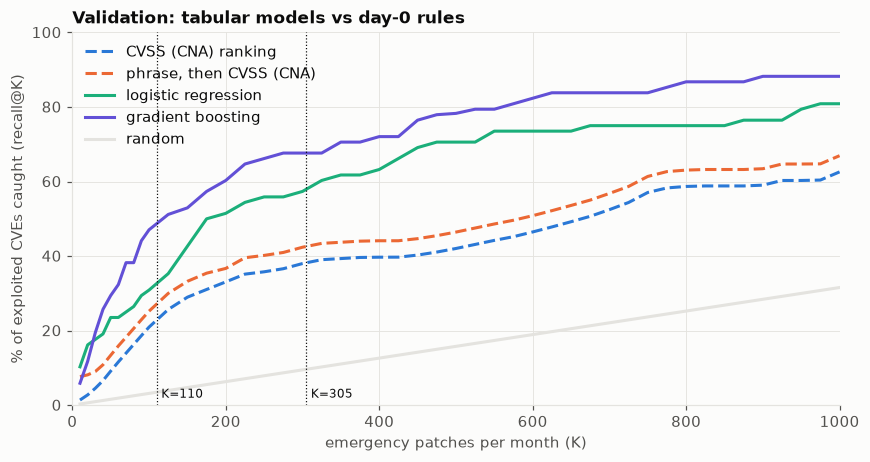

In [7]:
ks = np.unique(np.r_[np.arange(10, 100, 10), np.arange(100, 1001, 25)])
fig, ax = plt.subplots(figsize=(9, 4.4))
style = {"CVSS (CNA) ranking": (BLUE, "--"), "phrase, then CVSS (CNA)": (ORANGE, "--"),
         "logistic regression": (AQUA, "-"), "gradient boosting": (VIOLET, "-")}
for m, s in SC.items():
    c, ls = style[m]
    ax.plot(ks, 100 * recall_curve(val, s, ks), color=c, ls=ls, lw=2, label=m)
ax.plot(ks, [100 * random_recall_at_k(val, k) for k in ks], color=GRID, lw=2, label="random")
for k in (K_MAIN, K_GEN):
    ax.axvline(k, color=INK, lw=0.8, ls=":"); ax.annotate(f"K={k}", (k, 2), fontsize=8, xytext=(3, 0), textcoords="offset points")
ax.set_xlabel("emergency patches per month (K)"); ax.set_ylabel("% of exploited CVEs caught (recall@K)")
ax.set_ylim(0, 100); ax.set_xlim(0, 1000); ax.legend(frameon=False, loc="upper left")
ax.set_title("Validation: tabular models vs day-0 rules", loc="left")
save(fig, "05a_01_val_recall_vs_k")

**Takeaway**: Both models sit above both rules across the whole capacity range. At **K = 110 gradient boosting catches 32 of the 68 exploited CVEs where the best rule catches 19**. To match gradient boosting's 47% at K = 110, the best rule needs **520 patches/month, 4.7× the capacity**. Logistic regression stays between the rules and gradient boosting at small K and narrows the gap only at large K.

## 7. What the models rely on
Permutation importance on validation (drop in average precision when one feature is shuffled; interpretation
only, not used for any choice). SHAP explanations come in Phase 7.

,logistic regression,gradient boosting
cna,0.0407,0.0301
desc_len,0.0074,0.0300
cvss_cna_score,0.0105,0.0202
vendor_kev_log_all,0.0122,0.0182
cvss_PR,0.0099,0.0177
vendor_key,-0.0026,0.0113
cvss_AV,-0.0120,0.0110
cvss_I,-0.0033,0.0047
cwe,0.0190,0.0047
vendor_kev_log_365,0.0114,0.0013


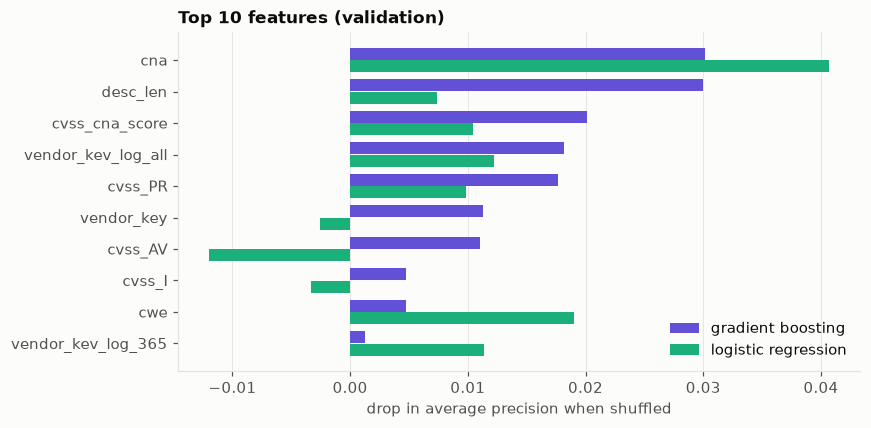

In [8]:
from sklearn.inspection import permutation_importance
imp = {}
for name, mdl in [("logistic regression", lr_model), ("gradient boosting", hgb_model)]:
    r = permutation_importance(mdl, X[is_val], y[is_val], scoring="average_precision", n_repeats=5, random_state=0)
    imp[name] = pd.Series(r.importances_mean, index=X.columns)
imp = pd.DataFrame(imp).sort_values("gradient boosting", ascending=False)
display(imp.head(10).round(4)); imp.to_csv(TAB / "05a_permutation_importance.csv")
top = imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
yy = np.arange(len(top))
ax.barh(yy + 0.2, top["gradient boosting"], height=0.38, color=VIOLET, label="gradient boosting")
ax.barh(yy - 0.2, top["logistic regression"], height=0.38, color=AQUA, label="logistic regression")
ax.set_yticks(yy, top.index); ax.grid(axis="y", visible=False); ax.legend(frameon=False, loc="lower right")
ax.set_xlabel("drop in average precision when shuffled"); ax.set_title("Top 10 features (validation)", loc="left")
save(fig, "05a_02_permutation_importance")

**Takeaway**: The models rely on **who** (CNA, vendor, and the vendor's earlier KEV entries), **how bad** (CNA CVSS score, privileges required, attack vector) and, surprisingly, **description length**. Because exploited CVEs' descriptions are edited more often, we tested description length directly: replacing each history-sample CVE's length with its **original** publication-day length leaves val recall unchanged (47.1% → 47.1% at K = 110, 67.6% → 67.6% at K = 305; score rank correlation 0.98). So it is a genuine day-0 signal, likely vendor writing style (e.g. Microsoft's very short titles), not an edit artefact. Dropping it costs ~9 points on val and 2023. Permutation importance on 68 positives is noisy (some LR values are slightly negative); Phase 7 adds SHAP.

## 8. Comparison table — all methods so far (validation + walk-forward)

In [9]:
def fmt(m, k):
    r = ci.loc[(m, k)]; return f"{100*r['point']:.1f} [{100*r['lo']:.0f}–{100*r['hi']:.0f}]"
lr_row, hgb_row = lr_res.iloc[0], hgb_res.iloc[0]
rows = [{"method": "random", "type": "reference", f"val recall@{K_MAIN} [CI]": f"{100*random_recall_at_k(val, K_MAIN):.1f}",
         f"val recall@{K_GEN} [CI]": f"{100*random_recall_at_k(val, K_GEN):.1f}", "WF 2023": "", "WF 2024-H1": "", "WF worst": "", "val PR-AUC": ""}]
for m in ["CVSS (CNA) ranking", "phrase, then CVSS (CNA)"]:
    r = rules_tbl.loc[m]
    rows.append({"method": m, "type": "day-0 rule", f"val recall@{K_MAIN} [CI]": fmt(m, K_MAIN), f"val recall@{K_GEN} [CI]": fmt(m, K_GEN),
                 "WF 2023": round(100*r[f"wf_2023@{K_MAIN}"], 1), "WF 2024-H1": round(100*r[f"wf_2024h1@{K_MAIN}"], 1),
                 "WF worst": round(100*r["wf_worst"], 1), "val PR-AUC": round(pr_auc(val, SC[m]), 3)})
rows.append({"method": "generous CVSS (fallback) ranking", "type": "rule with hindsight (upper bound)",
             f"val recall@{K_MAIN} [CI]": "15.1 [6–25]", f"val recall@{K_GEN} [CI]": "38.5 [27–51]", "WF 2023": "", "WF 2024-H1": "", "WF worst": "", "val PR-AUC": "0.011"})
for m, r in [("logistic regression", lr_row), ("gradient boosting", hgb_row)]:
    rows.append({"method": m, "type": "model (tabular)", f"val recall@{K_MAIN} [CI]": fmt(m, K_MAIN), f"val recall@{K_GEN} [CI]": fmt(m, K_GEN),
                 "WF 2023": round(100*r[f"wf_2023@{K_MAIN}"], 1), "WF 2024-H1": round(100*r[f"wf_2024h1@{K_MAIN}"], 1),
                 "WF worst": round(100*r["wf_worst"], 1), "val PR-AUC": round(pr_auc(val, SC[m]), 3)})
comp = pd.DataFrame(rows).set_index("method"); display(comp); comp.to_csv(TAB / "05a_comparison.csv")

,type,val recall@110 [CI],val recall@305 [CI],WF 2023,WF 2024-H1,WF worst,val PR-AUC
method,,,,,,,
random,reference,3.5,9.6,,,,
CVSS (CNA) ranking,day-0 rule,23.7 [13–33],38.3 [27–50],20.3,28.4,20.3,0.011
"phrase, then CVSS (CNA)",day-0 rule,28.1 [17–38],42.7 [31–55],39.3,34.9,34.9,0.069
generous CVSS (fallback) ranking,rule with hindsight (upper bound),15.1 [6–25],38.5 [27–51],,,,0.011
logistic regression,model (tabular),30.9 [21–43],58.8 [46–70],53.7,28.9,28.9,0.071
gradient boosting,model (tabular),47.1 [36–60],67.6 [57–79],39.7,55.6,39.7,0.049


**Takeaway**: Structured day-0 features alone already beat every rule. **Gradient boosting: 47.1% at K = 110 and 67.6% at K = 305 on validation** (three-period selection score 47.4%), vs 28.1% / 42.7% for the best rule and 23.7% / 38.3% for the current CVSS rule. It is the only method whose **worst** period (39.7%) stays above the best rule's worst (34.9%). Logistic regression (selection 37.8%) is unstable across periods and loses to the rule on 2024-H1. PR-AUC disagrees with recall@K (the boosting model has the lower PR-AUC, 0.049): PR-AUC rewards the whole ordering, while the team only patches the top ~3% of each month. Next (6b): add the description text.